<a href="https://colab.research.google.com/github/BrownParticleAstro/dmtools_notebooks/blob/main/notebook_dmtools_plot_demo_20261027_fill_diagnostics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Use the API client to get data

In [1]:
!pip install -i https://test.pypi.org/simple/ dmtools-brown-edu --upgrade

Looking in indexes: https://test.pypi.org/simple/


In [2]:
import json
from dmtools_brown_edu.dmtools_client_package.dmtools_quart import APIClient

In [3]:
from google.colab import userdata
api_key = userdata.get('DM_TOOLS')
email = userdata.get("DM_TOOLS_EMAIL")

In [4]:
Client = APIClient(email, api_key, suppress_logs=False)

In [5]:
# data_ids = [19176, 19177]
# colors = ["yellow", "green"]
data_ids = [19176]
colors = ["yellow"]
# styles = ["fill", "fill"]
styles = ["fill"]
display_list = []
for id in range(len(data_ids)):
  data = Client.read(id=data_ids[id])
  display = {
    "record": {
        "id": None,
        "type": "Display",
        "created": None,
        "updated": None,
        "archived": None
    },
    "properties": {
        "color": colors[id],
        "style": styles[id]
    },
    "data": data
  }
  display_list.append(display)

2026-10-27 11:12:13,175 - dmtools_brown_edu.dmtools_client_package.dmtools_quart - INFO - Calling read data API
INFO:dmtools_brown_edu.dmtools_client_package.dmtools_quart:Calling read data API
/usr/local/lib/python3.13/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'app.dmtools.brown.edu'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


### Get the new plot library

In [6]:
from google.colab import userdata
import subprocess
import base64
import os
import shutil

token = userdata.get("github_token")
auth = base64.b64encode(f"x-access-token:{token}".encode()).decode()

# Remove the directory if it already exists to avoid git clone conflict
if os.path.exists("/content/dmtools"):
    shutil.rmtree("/content/dmtools")

subprocess.run([
    "git",
    "-c", f"http.extraHeader=Authorization: Basic {auth}",
    "clone",
    "--branch", "plot_rework",
    "--single-branch",
    "https://github.com/BrownParticleAstro/dmtools.git",
    "/content/dmtools"
], check=True)

import sys

sys.path.insert(0, "/content/dmtools/basecode/main")

In [7]:
import sys
sys.path.insert(0, "/content/dmtools/basecode/main")

In [8]:
# @title
# %pip install -r /content/dmtools/basecode/main/requirements.txt

In [9]:
from app.libraries.plot_operations.v1.plot_operations import render_plot_from_data

/content/dmtools/basecode/main/app/libraries/shared_operations/v0/search_string.py:221: SyntaxWarning: invalid escape sequence '\w'
  key_value_pairs = re.findall(r"(\w+):([^\s]+)", user_query)


### Use the new context agnostic plot library to generate a plot using the data from above

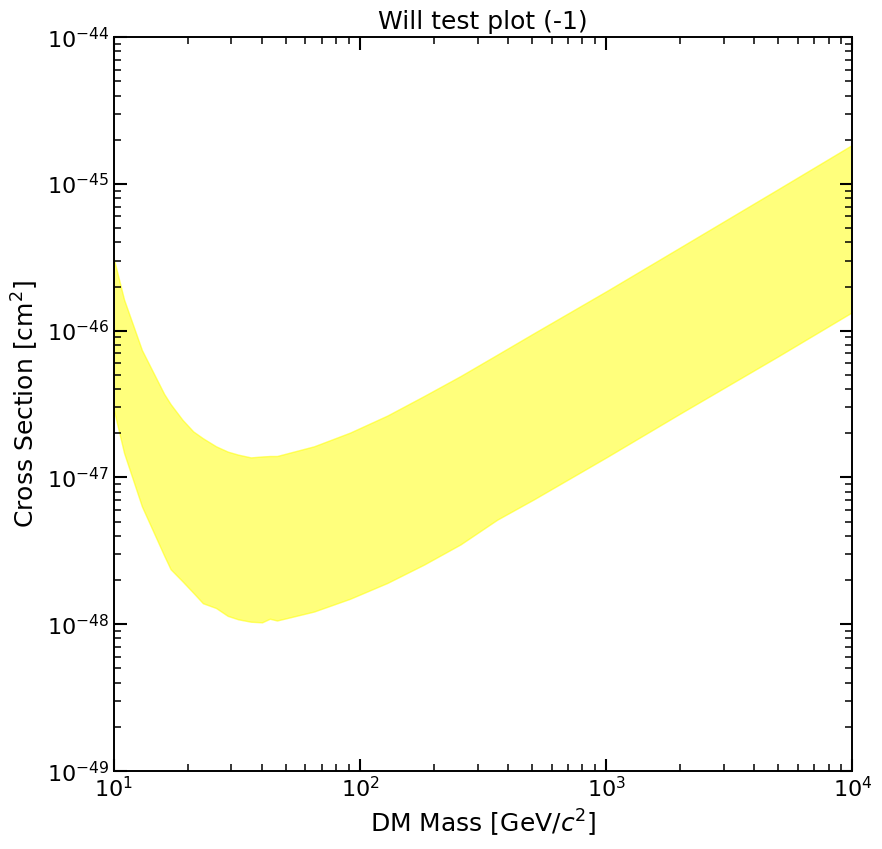

In [10]:
# We import the module again to ensure the changes to plot_operations.py are reloaded
import importlib
import app.libraries.plot_operations.v1.plot_operations
importlib.reload(app.libraries.plot_operations.v1.plot_operations)
from app.libraries.plot_operations.v1.plot_operations import render_plot_from_data

plot_id = -1
plot_properties = {'name': 'Will test plot', 'xMax': '10000', 'xMin': '10', 'yMax': '-44', 'yMin': '-49', 'no_id': 1, 'xUnits': 'GeV/c^2', 'yUnits': 'cm2'}
display_data_list = display_list
output_type = "notebook"
plot = await render_plot_from_data(plot_id, plot_properties, display_data_list, output_type=output_type)

In [11]:
type(plot[1])

matplotlib.figure.Figure

In [12]:
plot

('Will test plot', <Figure size 1000x1000 with 1 Axes>)

In [13]:
import os

def find_file(name, path):
    for root, dirs, files in os.walk(path):
        if name in files:
            return os.path.join(root, name)
    return None

# Let's locate the plot_operations.py file or similar files containing plotting logic
plot_ops_path = find_file('plot_operations.py', '/content/dmtools')
print(f"Found plot_operations at: {plot_ops_path}")

Found plot_operations at: /content/dmtools/basecode/main/app/libraries/plot_operations/v1/plot_operations.py


In [14]:
with open("/content/dmtools/basecode/main/app/libraries/plot_operations/v1/plot_operations.py", "r") as f:
    content = f.read()

# Let's search for 'fill' or 'fill_between' in the file to inspect the exact lines
lines = content.splitlines()
for idx, line in enumerate(lines):
    if "fill" in line.lower():
        # Print surrounding context (5 lines before and after)
        start = max(0, idx - 5)
        end = min(len(lines), idx + 10)
        print(f"--- Lines {start}-{end} ---")
        for i in range(start, end):
            print(f"{i}: {lines[i]}")
        print("\n" + "="*40 + "\n")

--- Lines 614-629 ---
614:         color = display_properties.get('color', 'black')
615: 
616:         # Get matplotlib kwargs from your style library
617:         line_plot_kwargs = get_style_mpl(color, style)
618:         line_plot_kwargs.pop('style', None)
619:         line_plot_kwargs.pop('fill', None)
620: 
621:         for data in display.get("data", []):
622:             data_properties = data.get('properties', {})
623: 
624:             y_rescale = float(data_properties.get('yRescale', 1))
625:             x_rescale = float(data_properties.get('xRescale', 1))
626:             x_units = data_properties.get('xUnits', 'GeV/c^2')
627: 
628:             trace_name = data_properties.get('label_short', 'Trace')


--- Lines 644-659 ---
644:                 else:
645:                     unit_x = [convert_mass_units(val, x_units, selected_unit) for val in x]
646: 
647:                 ax.plot(unit_x, y, **line_plot_kwargs)
648: 
649:                 if style == 'fill':
650:             

In [15]:
# Inspect the structure of display_list data we are passing in
import pprint

print(f"Number of data entries in the display: {len(display_list[0]['data'])}")
for idx, d in enumerate(display_list[0]['data']):
    print(f"\nEntry {idx} properties:")
    pprint.pprint(d.get('properties', {}))
    # Check data points length and structure
    points = d.get('data', [])
    print(f"Points length: {len(points)}")
    if points:
        print(f"First few points: {points[:3]}")

Number of data entries in the display: 1

Entry 0 properties:
{'comment': 'LZ 2025 2 sigma',
 'dateAnnouncement': '2025-07-01',
 'dateEnd': None,
 'dateOfficial': None,
 'dateStart': None,
 'defaultColor': 'blue',
 'defaultStyle': 'line',
 'experiment': 'LUX-ZEPLIN',
 'greatestHit': 0,
 'label': 'LZ 01 Jul 2025 WS2024 2 sigma',
 'label_short': 'LZ 1 Jul 2024 2 sigma',
 'measurementType': 'Dir',
 'official': 1,
 'open': 0,
 'public': 0,
 'rating': 80,
 'raw': '{[9 6.05e-47;\n'
        '11 1.47e-47;\n'
        '13 6.35e-48;\n'
        '16 2.94e-48;\n'
        '17 2.37e-48;\n'
        '19 1.96e-48;\n'
        '21 1.64e-48;\n'
        '23 1.39e-48;\n'
        '26 1.29e-48;\n'
        '29 1.14e-48;\n'
        '32 1.08e-48;\n'
        '36 1.04e-48;\n'
        '40 1.03e-48;\n'
        '43 1.09e-48;\n'
        '46 1.06e-48;\n'
        '65 1.22e-48;\n'
        '91 1.49e-48;\n'
        '129 1.91e-48;\n'
        '182 2.55e-48;\n'
        '256 3.50e-48;\n'
        '361 5.16e-48;\n'
        '508 7.

In [16]:
filepath = "/content/dmtools/basecode/main/app/libraries/plot_operations/v1/plot_operations.py"

with open(filepath, "r") as f:
    code_content = f.read()

# Let's inspect the exact lines we want to replace around style == 'fill'
# We want to replace lines 649-657:
#                 if style == 'fill':
#                     fill_plot_kwargs = get_style_mpl(color, style)
#                     fill_plot_kwargs.pop('style', None)
#                     fill_plot_kwargs.pop('marker', None)
#                     fill_plot_kwargs.pop('markersize', None)
#                     fill_plot_kwargs.pop('linestyle', None)
#                     fill_plot_kwargs.pop('linewidth', None)
#                     fill_plot_kwargs.pop('fill', None)
#                     ax.fill_between(unit_x, y, **fill_plot_kwargs)

# Instead, if the data object has multiple curves (i.e. if we can obtain both boundaries),
# we should use fill_between(unit_x, y_lower, y_upper).
# Since the loop goes through `for data in display.get("data", []):` and parses `x` and `y`:
# Let's modify the code so that if there are multiple lines (like in a band/fill scenario) we fill between them.

target_code = """                if style == 'fill':
                    fill_plot_kwargs = get_style_mpl(color, style)
                    fill_plot_kwargs.pop('style', None)
                    fill_plot_kwargs.pop('marker', None)
                    fill_plot_kwargs.pop('markersize', None)
                    fill_plot_kwargs.pop('linestyle', None)
                    fill_plot_kwargs.pop('linewidth', None)
                    fill_plot_kwargs.pop('fill', None)
                    ax.fill_between(unit_x, y, **fill_plot_kwargs)"""

replacement_code = """                if style == 'fill':
                    fill_plot_kwargs = get_style_mpl(color, style)
                    fill_plot_kwargs.pop('style', None)
                    fill_plot_kwargs.pop('marker', None)
                    fill_plot_kwargs.pop('markersize', None)
                    fill_plot_kwargs.pop('linestyle', None)
                    fill_plot_kwargs.pop('linewidth', None)
                    fill_plot_kwargs.pop('fill', None)
                    # If values contains multiple datasets (e.g. lower and upper bounds), fill between them
                    raw_values = data_properties.get('values', [])
                    if len(raw_values) >= 2:
                        y_lower = [val[1] * y_rescale for val in raw_values[0]]
                        y_upper = [val[1] * y_rescale for val in raw_values[1]]
                        # Ensure length match
                        min_len = min(len(unit_x), len(y_lower), len(y_upper))
                        ax.fill_between(unit_x[:min_len], y_lower[:min_len], y_upper[:min_len], **fill_plot_kwargs)
                    else:
                        ax.fill_between(unit_x, y, **fill_plot_kwargs)"""

if target_code in code_content:
    new_code_content = code_content.replace(target_code, replacement_code)
    with open(filepath, "w") as f:
        f.write(new_code_content)
    print("Successfully modified plot_operations.py to support bands between two limits!")
else:
    print("Target code block not found! Checking exact formatting...")

Target code block not found! Checking exact formatting...
